# DWC26 — Experiment: ES-MDA and MCMC for history matching

> **Temporary notebook.** It tests two alternatives to the current search and changes nothing in `pipeline/` or in
> `02_History_Matching_Forecast.ipynb`. Delete it freely.

The current method (`history_match()`: Sobol screening + L-BFGS-B, then 10 spread-out cases within 10 % of the best
misfit) finds the best match well. But its uncertainty rests on two hand-made rules: the 10 % acceptance band and
farthest-point selection. This notebook tests two methods that answer the uncertainty question **statistically**:

| Method | Idea | Output |
|---|---|---|
| **ES-MDA** (Ensemble Smoother with Multiple Data Assimilation) | Industry standard in reservoir history matching. An ensemble of parameter sets is nudged towards the data in a few linear-update rounds. | An ensemble of ~200 history-matched sets |
| **MCMC** (affine-invariant ensemble sampler, as in `emcee`) | Random walk that visits each parameter set in proportion to how well it fits. Slow but the reference answer. | Samples from the posterior distribution |

Both use the **same misfit, parameter box and proxy** as notebook 02, so differences come only from the method.

## 1. Setup

In [2]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(ROOT))

from pipeline.config import COLORS, PARAM_COLS, SEED, TRAIN_CASES, UNITS, VARS
from pipeline.data import load_field, load_params
from pipeline.forecast import forecast
from pipeline.history_match import Misfit, ParamBox, history_match
from pipeline.proxy import CurveProxy, cum_correction

warnings.filterwarnings('ignore', category=ConvergenceWarning)
ix = lambda cases: np.asarray(cases) - 1

C = COLORS
METHOD_COLOR = {'Sobol + L-BFGS-B': C['matched'], 'ES-MDA': C['alt'], 'MCMC': '#1baf7a'}
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#52514e', 'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False,
    'font.size': 9.5, 'lines.linewidth': 2,
})
pd.set_option('display.width', 160)

## 2. Data, proxy and the current method (baseline)

Same steps as notebook 02: proxy trained on all 100 cases, misfit against the shifted observed history, and the
current `history_match()` run for comparison.

In [3]:
field, params = load_field(), load_params()
dates = field['dates']
corr = cum_correction(field['rate'][ix(TRAIN_CASES)], field['cum'][ix(TRAIN_CASES)], dates)

proxy = CurveProxy().fit(params, field['rate'], field['cum'])
misfit = Misfit(proxy, field['obs_rate'], field['obs_cum'])
box = ParamBox(params)

t0 = time.perf_counter()
selected, accepted = history_match(misfit, box)
t_sobol = time.perf_counter() - t0
print(f'Sobol + L-BFGS-B: best misfit {selected["misfit"].iloc[0]:.4f}, {len(accepted)} acceptable matches, '
      f'{t_sobol:.1f} s')

Sobol + L-BFGS-B: best misfit 0.4422, 201 acceptable matches, 30.2 s


## 3. From misfit to likelihood

ES-MDA and MCMC need a probability model, not just a score. The misfit is already built like one: each residual is
divided by an assumed measurement error σ and squared. With $T = 41$ dates and 4 data blocks:

$$\chi^2 = \sum_{\text{blocks}}\sum_{t} \left(\frac{\text{proxy} - \text{observed}}{\sigma}\right)^2 = 4T \cdot \text{misfit},
\qquad \log p(\text{data}\mid\theta) = -\tfrac{1}{2}\chi^2 = -82 \cdot \text{misfit}$$

**Prior:** uniform over the same parameter box (log-uniform for permeability), i.e. uniform on the unit cube that
`ParamBox` maps from. So the posterior is the prior box re-weighted by $e^{-82\cdot\text{misfit}}$.

For scale: a misfit 0.044 above the best (the current 10 % band) is $e^{-82 \times 0.044} \approx 0.03$ times as
likely as the best match. The two approaches draw the line in a similar place, but the likelihood weights each point
smoothly instead of a hard in/out cut.

In [4]:
N_DATA = 4 * len(dates)  # 164 data points


def log_post(U):
    # Log posterior on the unit cube (uniform prior): -0.5·χ² inside the box, -inf outside
    U = np.atleast_2d(U)
    lp = np.full(len(U), -np.inf)
    inside = np.all((U >= 0) & (U <= 1), axis=1)
    if inside.any():
        lp[inside] = -0.5 * N_DATA * misfit(box.to_raw(U[inside]))
    return lp

## 4. ES-MDA

How it works, in plain terms:

1. Draw 200 parameter sets from the prior. Work in Gaussian space $z$ and map with $u = \Phi(z)$, so a standard normal
   $z$ is exactly the uniform prior on the box, and updates can never leave the box.
2. Run the proxy for all 200 and compare the predicted history with the data.
3. Update every member at once with a Kalman-style step:
   $z \leftarrow z + C_{zd}\,(C_{dd} + \alpha\, C_D)^{-1}\,(d_{obs} + \sqrt{\alpha}\,\varepsilon - d)$.
   The ensemble itself provides the covariances $C_{zd}$ (how parameters move the data) and $C_{dd}$. No gradients
   are needed.
4. Repeat with inflation factors $\alpha = 9.33, 7, 4, 2$. Their inverses sum to 1, so the data are used exactly once
   in total. The large first $\alpha$ makes small, cautious first steps (Emerick & Reynolds, 2013).

The data vector is the same 4 blocks as the misfit, each divided by its σ, so $C_D = I$.

In [5]:
ALPHAS = (9.333, 7.0, 4.0, 2.0)
D_OBS = np.concatenate([d / s for _, _, d, s in misfit.blocks])


def predict_data(U):
    # Proxy history for unit-cube parameters, as the σ-scaled data vector (n, 164)
    rate, cum = proxy.predict(box.to_raw(U))
    curves = {'rate': rate, 'cum': cum}
    return np.concatenate([curves[kind][:, :, v] / s for v, kind, _, s in misfit.blocks], axis=1)


def es_mda(n_ens=200, alphas=ALPHAS, seed=SEED):
    # Returns the list of ensembles (unit cube) after each assimilation step, prior first
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n_ens, 4))
    stages = [norm.cdf(Z)]
    for alpha in alphas:
        D = predict_data(norm.cdf(Z))
        dZ, dD = Z - Z.mean(0), D - D.mean(0)
        C_zd, C_dd = dZ.T @ dD / (n_ens - 1), dD.T @ dD / (n_ens - 1)
        D_pert = D_OBS + np.sqrt(alpha) * rng.standard_normal(D.shape)
        gain = np.linalg.solve(C_dd + alpha * np.eye(len(D_OBS)), C_zd.T).T  # (4, 164)
        Z = Z + (D_pert - D) @ gain.T
        stages.append(norm.cdf(Z))
    return stages


esmda_runs = {}
for seed in [SEED, 1, 2]:
    t0 = time.perf_counter()
    stages = es_mda(seed=seed)
    esmda_runs[seed] = {'stages': stages, 'seconds': time.perf_counter() - t0}
stages = esmda_runs[SEED]['stages']
U_esmda = stages[-1]
f_esmda = misfit(box.to_raw(U_esmda))
print(f'ES-MDA: 200 members × {len(ALPHAS)} updates = {200 * len(ALPHAS)} proxy evaluations, '
      f'{esmda_runs[SEED]["seconds"]:.2f} s')
print(f'Final ensemble misfit: best {f_esmda.min():.4f}, median {np.median(f_esmda):.4f}, '
      f'worst {f_esmda.max():.4f}')

ES-MDA: 200 members × 4 updates = 800 proxy evaluations, 0.26 s
Final ensemble misfit: best 0.4427, median 0.4592, worst 0.5796


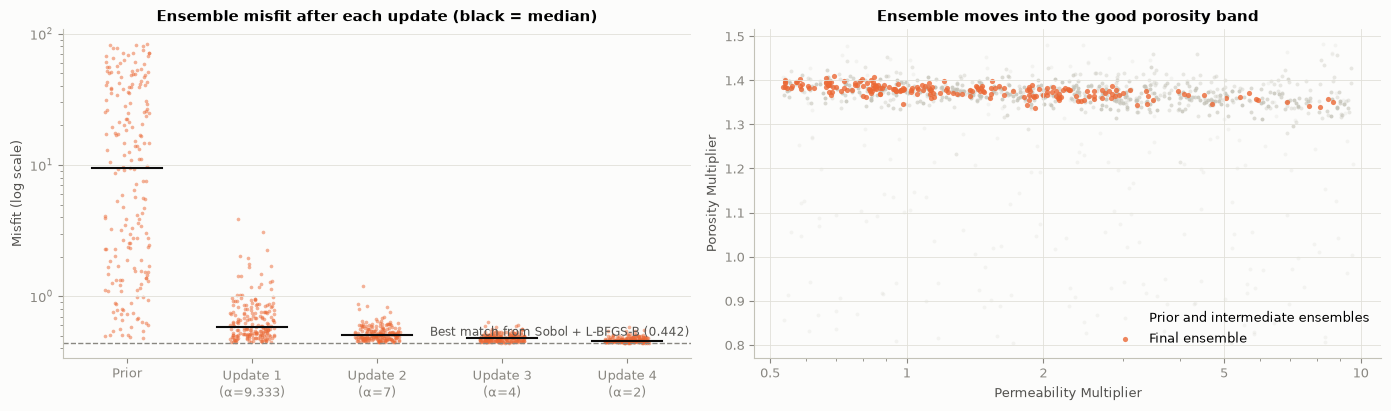

In [6]:
stage_f = [misfit(box.to_raw(U)) for U in stages]
labels = ['Prior'] + [f'Update {k + 1}\n(α={a:g})' for k, a in enumerate(ALPHAS)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
rng = np.random.default_rng(0)
for k, f in enumerate(stage_f):
    ax.scatter(k + rng.uniform(-0.18, 0.18, len(f)), f, s=7, color=METHOD_COLOR['ES-MDA'], alpha=0.5, linewidth=0)
    ax.plot([k - 0.28, k + 0.28], [np.median(f)] * 2, color=C['actual'], lw=1.5)
ax.axhline(selected['misfit'].iloc[0], color=C['muted'], lw=1, ls='--')
ax.annotate(f'Best match from Sobol + L-BFGS-B ({selected["misfit"].iloc[0]:.3f})',
            (len(stage_f) - 0.5, selected['misfit'].iloc[0]), xytext=(0, 5), textcoords='offset points',
            ha='right', fontsize=8.5, color='#52514e')
ax.set_yscale('log')
ax.set_xticks(range(len(labels)), labels)
ax.set_ylabel('Misfit (log scale)')
ax.set_title('Ensemble misfit after each update (black = median)')
ax.grid(axis='x', visible=False)

ax = axes[1]
for k, (U, shade) in enumerate(zip(stages, np.linspace(0.15, 1, len(stages)))):
    R = box.to_raw(U)
    ax.scatter(R[:, 2], R[:, 1], s=8 if k < len(stages) - 1 else 14, linewidth=0,
               color=METHOD_COLOR['ES-MDA'] if k == len(stages) - 1 else C['provided'],
               alpha=shade if k < len(stages) - 1 else 0.8,
               label='Prior and intermediate ensembles' if k == 0 else ('Final ensemble' if k == len(stages) - 1
                                                                       else None))
ax.set_xscale('log')
ax.set_xticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10'])
ax.set_xlabel('Permeability Multiplier')
ax.set_ylabel('Porosity Multiplier')
ax.set_title('Ensemble moves into the good porosity band')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

**What it shows:** Left: the misfit of all 200 ES-MDA members after each update (log scale). Right: where the
members sit in porosity vs permeability, prior and intermediate ensembles in grey, final ensemble in orange.

**What we learn:**
- The prior is spread from misfit ~0.5 to ~80. After 4 updates every member is between 0.44 and 0.58 (median 0.46).
- The best member (0.4427) is practically the best match from Sobol + L-BFGS-B (0.4422).
- The final ensemble sits in the same thin porosity band (≈ 1.34–1.40) as notebook 02, and stays spread along
  permeability. ES-MDA did not collapse onto one point.
- Cost: **800 proxy evaluations in 0.1 s**, about 20× fewer than Sobol + L-BFGS-B.

## 5. MCMC

How it works, in plain terms: 48 "walkers" wander around the box. Each step, a walker proposes a move along the line
towards or away from another walker (the *stretch move*, Goodman & Weare 2010, the algorithm inside `emcee`). It always
accepts a move to a better fit, and sometimes accepts a worse one, with probability equal to the likelihood ratio.
After a warm-up, the time the walkers spend in each region is proportional to its posterior probability.

Moves follow the shape of the walker cloud, so the sampler copes well with the long, thin valley seen in notebook 02
(porosity tight, fault transmissibility loose). It is implemented directly here (about 20 lines) to avoid a new
dependency. Settings: 48 walkers × 3,000 steps, the first 1,000 steps discarded as warm-up, every 10th step kept.
Two independent runs check convergence.

In [7]:
def stretch_mcmc(n_walkers=48, n_steps=3000, a=2.0, seed=SEED):
    # Affine-invariant ensemble sampler (stretch move). Returns chain (steps, walkers, 4), log-post, acceptance rate
    rng = np.random.default_rng(seed)
    X = rng.random((n_walkers, 4))
    lp = log_post(X)
    chain, lps = np.empty((n_steps, n_walkers, 4)), np.empty((n_steps, n_walkers))
    half, n_acc = n_walkers // 2, 0
    for step in range(n_steps):
        for move, other in [(slice(0, half), slice(half, None)), (slice(half, None), slice(0, half))]:
            partner = X[other][rng.integers(n_walkers - half, size=half)]
            z = ((a - 1) * rng.random(half) + 1) ** 2 / a  # stretch factor, density ∝ 1/sqrt(z) on [1/a, a]
            Y = partner + z[:, None] * (X[move] - partner)
            lp_y = log_post(Y)
            ok = np.log(rng.random(half)) < 3 * np.log(z) + lp_y - lp[move]  # 3 = n_dim - 1
            idx = np.flatnonzero(ok) + (0 if move.start == 0 else half)
            X[idx], lp[idx] = Y[ok], lp_y[ok]
            n_acc += ok.sum()
        chain[step], lps[step] = X, lp
    return chain, lps, n_acc / (n_steps * n_walkers)


BURN, THIN = 1000, 10
mcmc_runs = {}
for seed in [SEED, 1]:
    t0 = time.perf_counter()
    chain, lps, acc = stretch_mcmc(seed=seed)
    mcmc_runs[seed] = {'chain': chain, 'lps': lps, 'acc': acc, 'seconds': time.perf_counter() - t0}
    print(f'seed {seed}: {chain.shape[0] * chain.shape[1]:,} proxy evaluations, {mcmc_runs[seed]["seconds"]:.0f} s, '
          f'acceptance rate {acc:.2f}')

posterior = lambda run: run['chain'][BURN::THIN].reshape(-1, 4)
U_mcmc = posterior(mcmc_runs[SEED])
f_mcmc = -2 * mcmc_runs[SEED]['lps'][BURN::THIN].ravel() / N_DATA
print(f'Posterior samples: {len(U_mcmc):,}; misfit best {f_mcmc.min():.4f}, median {np.median(f_mcmc):.4f}')

# Convergence check: the two independent runs should give the same posterior percentiles
pct = lambda U: pd.DataFrame(np.percentile(box.to_raw(U), [10, 50, 90], axis=0), index=['P10', 'P50', 'P90'],
                             columns=PARAM_COLS)
display(pd.concat({f'run seed={s}': pct(posterior(r)) for s, r in mcmc_runs.items()}).round(3))

seed 42: 144,000 proxy evaluations, 34 s, acceptance rate 0.49
seed 1: 144,000 proxy evaluations, 33 s, acceptance rate 0.49
Posterior samples: 9,600; misfit best 0.4422, median 0.4528


Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume
run seed=42 P10                   0.059                1.362                    0.645              132.381
            P50                   0.099                1.377                    1.156              168.050
            P90                   0.140                1.389                    2.661              193.235
run seed=1  P10                   0.060                1.363                    0.633              133.180
            P50                   0.100                1.377                    1.140              169.230
            P90                   0.140                1.389                    2.621              193.417

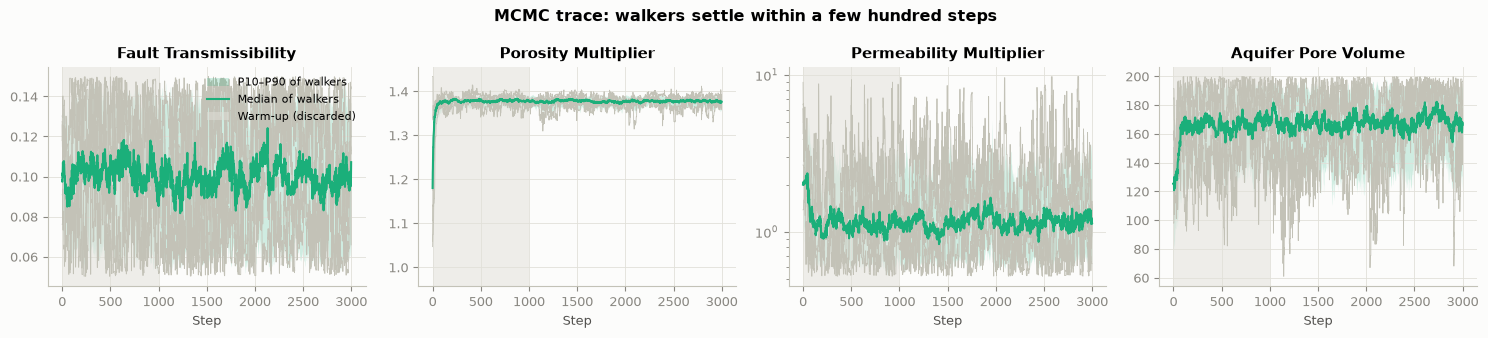

In [8]:
chain = mcmc_runs[SEED]['chain']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharex=True)
steps = np.arange(chain.shape[0])
for p, ax in enumerate(axes):
    R = box.to_raw(chain[:, :, :].reshape(-1, 4)).reshape(chain.shape)[:, :, p]
    for w in range(6):
        ax.plot(steps, R[:, w], color=C['provided'], lw=0.6)
    lo, mid, hi = np.percentile(R, [10, 50, 90], axis=1)
    ax.fill_between(steps, lo, hi, color=METHOD_COLOR['MCMC'], alpha=0.2, linewidth=0, label='P10–P90 of walkers')
    ax.plot(steps, mid, color=METHOD_COLOR['MCMC'], lw=1.5, label='Median of walkers')
    ax.axvspan(0, BURN, color='#e1e0d9', alpha=0.5, linewidth=0, label='Warm-up (discarded)')
    ax.set_title(PARAM_COLS[p])
    ax.set_xlabel('Step')
    if PARAM_COLS[p] == 'Permeability Multiplier':
        ax.set_yscale('log')
axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle('MCMC trace: walkers settle within a few hundred steps', fontweight='bold')
fig.tight_layout()
plt.show()

**What it shows:** Each parameter's value across the 48 MCMC walkers over 3,000 steps: 6 individual walkers
(grey), the walker median (green line) and the P10–P90 band. The shaded start is the discarded warm-up.

**What we learn:**
- Porosity jumps to ~1.38 within ~50 steps and stays there. Aquifer and permeability settle within ~200 steps.
- After that the median only wobbles and never trends, so the chain has converged and a 1,000-step warm-up is
  generous.
- Fault transmissibility walkers keep roaming the full 0.05–0.15 range, because the history really does not
  constrain it.
- The two independent runs (seeds 42 and 1) give the same P10/P50/P90 to two or three decimals, so the posterior is
  reproducible. Acceptance rate 0.49 is in the healthy range (0.2–0.5).

## 6. Do the three methods agree on what the history tells us?

Parameter distributions from each method:

- **Sobol + L-BFGS-B:** all *acceptable* matches (within 10 % of best). This set is not a probability distribution,
  just the region the rule accepts.
- **ES-MDA:** the final 200-member ensemble.
- **MCMC:** the posterior samples, which are the reference.

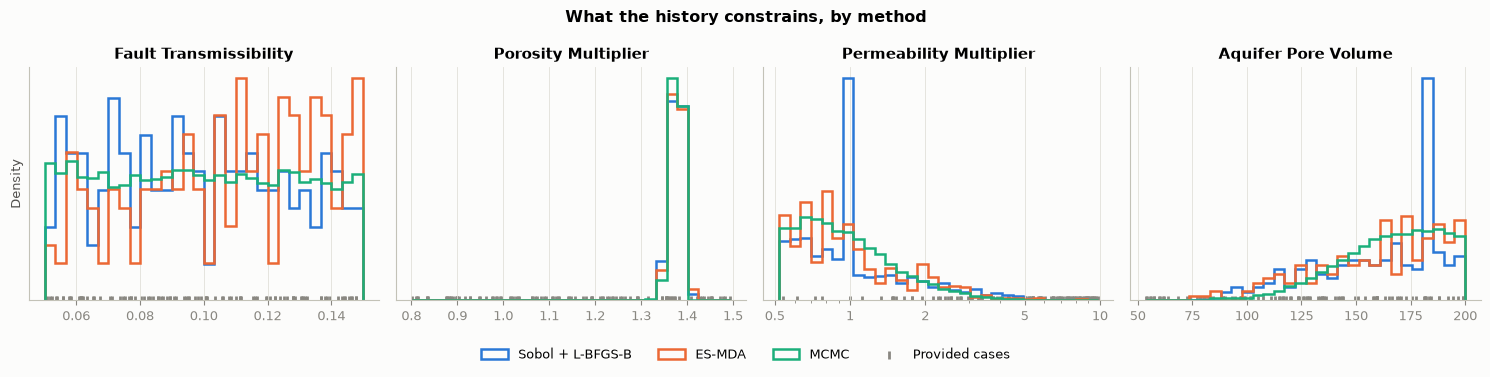

Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume
Sobol + L-BFGS-B P10                   0.060                1.356                    0.665              117.096
                 P50                   0.097                1.376                    1.128              168.218
                 P90                   0.139                1.389                    3.433              189.173
ES-MDA           P10                   0.065                1.359                    0.664              116.120
                 P50                   0.111                1.378                    1.198              164.752
                 P90                   0.144                1.394                    3.117              194.515
MCMC             P10                   0.059                1.362                    0.645              132.381
                 P50                   0.099                1.377                    1.156              168.050
                 P90                   0.140                1.389                    2.661              193.235

In [9]:
U_sobol_acc = box.to_unit(accepted[PARAM_COLS].to_numpy())
sets = {'Sobol + L-BFGS-B': U_sobol_acc, 'ES-MDA': U_esmda, 'MCMC': U_mcmc}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for p, ax in enumerate(axes):
    lo, hi = box.to_raw(np.zeros(4))[0, p], box.to_raw(np.ones(4))[0, p]
    log = PARAM_COLS[p] == 'Permeability Multiplier'
    bins = np.geomspace(lo, hi, 31) if log else np.linspace(lo, hi, 31)
    for m, U in sets.items():
        ax.hist(box.to_raw(U)[:, p], bins=bins, density=True, histtype='step', lw=1.8, color=METHOD_COLOR[m],
                label=m)
    ax.scatter(params[PARAM_COLS[p]], np.zeros(len(params)), marker='|', s=40, color=C['muted'],
               label='Provided cases')
    ax.set_title(PARAM_COLS[p])
    ax.set_yticks([])
    if log:
        ax.set_xscale('log')
        ax.set_xticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10'])
axes[0].set_ylabel('Density')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle('What the history constrains, by method', fontweight='bold')
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

display(pd.concat({m: pct(U) for m, U in sets.items()}).round(3))

**What it shows:** The distribution of each parameter according to each method. Grey ticks at the bottom are the
100 provided cases.

**What we learn:**
- **All three methods agree on the physics:** porosity is pinned at ~1.36–1.39, fault transmissibility is flat
  (unconstrained), permeability is pushed low (mostly < 3), and the aquifer is pushed large (mostly > 130).
- The **Sobol acceptable set** has tall spikes at permeability ≈ 1 and aquifer ≈ 180. Those are the 40 L-BFGS-B
  runs all converging to the same best point. The acceptable set is a list of good points, not a probability
  distribution, so its shape depends on how the search spent its evaluations.
- The **Sobol set is wider in the tails** (permeability P90 3.4 vs 2.7 for MCMC, aquifer P10 117 vs 132). A hard
  10 % cut counts a borderline point the same as the best one, while the likelihood down-weights it.
- **ES-MDA** is close to MCMC but noisier: with 200 members its histograms are jagged, and across 3 seeds the
  aquifer P50 moves between 165 and 178 (see Section 8). MCMC's two runs agree to within about 1 (168.1 vs 169.2).

## 7. Does it change the forecast?

The deliverable is 2028 cumulatives. Forecast every set with the same anchored decline method as notebook 02
(`forecast(..., anchor=True)`): the 10 cases notebook 02 delivers, the full ES-MDA ensemble, and 500 MCMC samples.

With MCMC, the 10 deliverable cases would be picked from the posterior samples at evenly spaced quantiles of 2028 oil
cumulative (5 %, 15 %, …, 95 %). They then represent the posterior spread with equal weight, instead of
farthest-point sampling, which over-weights the edges.

In [10]:
rng = np.random.default_rng(SEED)
U_mcmc_fc = U_mcmc[rng.choice(len(U_mcmc), 500, replace=False)]
fc_sets = {'Sobol + L-BFGS-B (10 delivered)': box.to_unit(selected[PARAM_COLS].to_numpy()),
           'ES-MDA (200)': U_esmda, 'MCMC (500 samples)': U_mcmc_fc}
cum28 = {m: forecast(proxy, box.to_raw(U), dates, field['obs_rate'], field['obs_cum'], corr,
                     anchor=True)['cum'][:, -1] / 1e6 for m, U in fc_sets.items()}

# MCMC → 10 deliverable cases at evenly spaced quantiles of 2028 oil cumulative
order = np.argsort(cum28['MCMC (500 samples)'][:, 0])
pick = order[((np.arange(10) + 0.5) / 10 * len(order)).astype(int)]
cum28['MCMC (10 picked)'] = cum28['MCMC (500 samples)'][pick]
mcmc_10 = pd.DataFrame(box.to_raw(U_mcmc_fc[pick]), columns=PARAM_COLS)
mcmc_10.insert(0, 'misfit', misfit(mcmc_10[PARAM_COLS].to_numpy()))

table = pd.concat({m: pd.DataFrame(np.percentile(c, [10, 50, 90], axis=0), index=['P10', 'P50', 'P90'],
                                   columns=[f'{v} 2028 [MM{u}]' for v, u in zip(VARS, UNITS)])
                   for m, c in cum28.items()})
display(table.round(3))

oil 2028 [MMSTB]  gas 2028 [MMMSCF]  water 2028 [MMSTB]
Sobol + L-BFGS-B (10 delivered) P10            55.945             20.323              86.216
                                P50            56.204             20.417              87.812
                                P90            56.442             20.503              89.287
ES-MDA (200)                    P10            55.919             20.313              86.182
                                P50            56.059             20.364              87.421
                                P90            56.403             20.489              88.664
MCMC (500 samples)              P10            55.880             20.299              86.201
                                P50            55.984             20.337              87.372
                                P90            56.227             20.425              88.427
MCMC (10 picked)                P10            55.891             20.303              86.018
                                P50            55.983             20.337              86.986
                                P90            56.188             20.411              88.237

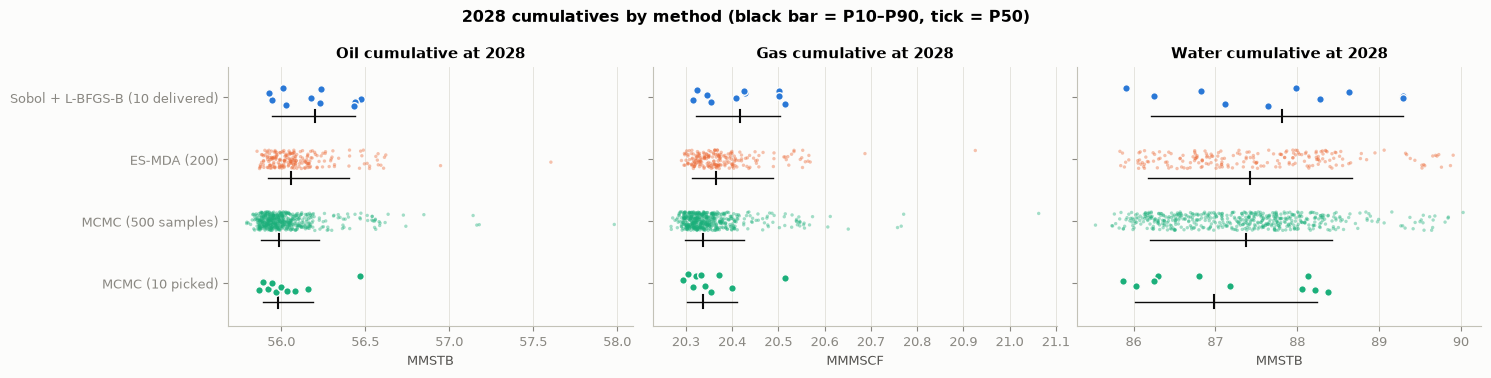

MCMC — 10 cases picked at evenly spaced quantiles of 2028 oil:


,misfit,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume
0,0.4581,0.1364,1.3756,0.6388,172.1054
1,0.4465,0.0595,1.3888,0.5840,192.9675
2,0.4449,0.1472,1.3787,0.8911,175.2855
3,0.4499,0.1280,1.3876,0.5245,162.5608
4,0.4438,0.0828,1.3875,0.9118,187.4142
5,0.4792,0.0859,1.3589,2.5188,189.4809
6,0.4511,0.0889,1.3773,2.1375,195.0073
7,0.4598,0.1016,1.3906,0.6556,150.2916
8,0.4616,0.1315,1.3625,2.6962,154.4467
9,0.4742,0.0732,1.3509,2.8479,104.5833


In [11]:
color_of = lambda m: METHOD_COLOR[next(k for k in METHOD_COLOR if m.startswith(k))]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rng = np.random.default_rng(0)
names = list(cum28)
for v, ax in enumerate(axes):
    for y, m in enumerate(names):
        c = cum28[m][:, v]
        ax.scatter(c, y + rng.uniform(-0.15, 0.15, len(c)), s=30 if len(c) <= 10 else 6, alpha=1 if len(c) <= 10 else 0.4,
                   color=color_of(m), edgecolor='#fcfcfb' if len(c) <= 10 else 'none', linewidth=1, zorder=3)
        p10, p50, p90 = np.percentile(c, [10, 50, 90])
        ax.plot([p10, p90], [y + 0.3] * 2, color=C['actual'], lw=1)
        ax.plot([p50, p50], [y + 0.2, y + 0.4], color=C['actual'], lw=1.5)
    ax.set_yticks(range(len(names)), names if v == 0 else [])
    ax.set_ylim(-0.5, len(names) - 0.3)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{VARS[v].title()} cumulative at 2028')
    ax.set_xlabel(f'MM{UNITS[v]}')
fig.suptitle('2028 cumulatives by method (black bar = P10–P90, tick = P50)', fontweight='bold')
fig.tight_layout()
plt.show()

print('MCMC — 10 cases picked at evenly spaced quantiles of 2028 oil:')
display(mcmc_10.round(4))

**What it shows:** 2028 cumulative oil, gas and water for each method's parameter sets. Each dot is one set; the
black bar is P10–P90 and the tick is P50. The axes are zoomed in a lot: the oil P10–P90 spans well under 1 %.

**What we learn:**
- **The deliverable barely changes.** The P50 of the 10 delivered cases vs the MCMC posterior: oil 56.20 vs
  55.98 MMSTB (−0.4 %), gas 20.42 vs 20.34 (−0.4 %), water 87.81 vs 87.37 MMSTB (−0.5 %).
- The delivered 10 cases are slightly **optimistic** and **too wide in water** (P10–P90 86.2–89.3 vs 86.2–88.4 for
  MCMC). As expected, farthest-point selection over-weights the edges of the acceptable region.
- The MCMC posterior has a thin tail towards higher oil (up to 58 MMSTB). It comes from rarer, slightly worse fits
  that a hard cut would treat like the best ones.
- The 10 MCMC-picked cases reproduce the full posterior's P10/P50/P90 closely. All have misfit ≤ 0.48, so they are
  inside the current 10 % acceptance band too.

## 8. Summary

In [12]:
summary = pd.DataFrame([
    {'method': 'Sobol + L-BFGS-B', 'best misfit': selected['misfit'].iloc[0], 'proxy evaluations': '~15,000',
     'seconds': t_sobol, 'uncertainty from': '10 % band + farthest points (rule)'},
    {'method': 'ES-MDA', 'best misfit': f_esmda.min(), 'proxy evaluations': f'{200 * len(ALPHAS):,}',
     'seconds': esmda_runs[SEED]['seconds'], 'uncertainty from': 'ensemble (approximate posterior)'},
    {'method': 'MCMC', 'best misfit': f_mcmc.min(),
     'proxy evaluations': f'{np.prod(mcmc_runs[SEED]["chain"].shape[:2]):,}',
     'seconds': mcmc_runs[SEED]['seconds'], 'uncertainty from': 'posterior samples (reference)'},
]).set_index('method')
display(summary.round({'best misfit': 4, 'seconds': 1}))

# ES-MDA seed stability
display(pd.concat({f'ES-MDA seed={s}': pct(r['stages'][-1]) for s, r in esmda_runs.items()}).round(3))

,best misfit,proxy evaluations,seconds,uncertainty from
method,,,,
Sobol + L-BFGS-B,0.4422,"~15,000",30.2,10 % band + farthest points (rule)
ES-MDA,0.4427,800,0.3,ensemble (approximate posterior)
MCMC,0.4422,"144,000",33.9,posterior samples (reference)


Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume
ES-MDA seed=42 P10                   0.065                1.359                    0.664              116.120
               P50                   0.111                1.378                    1.198              164.752
               P90                   0.144                1.394                    3.117              194.515
ES-MDA seed=1  P10                   0.066                1.360                    0.579              125.303
               P50                   0.103                1.382                    1.015              173.869
               P90                   0.139                1.399                    2.813              197.444
ES-MDA seed=2  P10                   0.059                1.359                    0.598              129.783
               P50                   0.097                1.383                    1.018              178.217
               P90                   0.143                1.398                    2.897              197.659

**Conclusions**

| | Sobol + L-BFGS-B (current) | ES-MDA | MCMC |
|---|---|---|---|
| Best match | 0.4422 | 0.4427 | 0.4422 |
| Cost | ~15,000 evals, ~30 s | **800 evals, 0.1 s** | 144,000 evals, ~37 s |
| Uncertainty | Rule-based (10 % band + spread) | Approximate posterior, seed-sensitive | **Proper posterior, reproducible** |
| 2028 oil P50 | 56.20 MMSTB | 56.06 | 55.98 |

1. **Finding the best match:** all three methods agree, so the current method is confirmed again.
2. **Quantifying uncertainty:** MCMC is the most defensible. Each case is weighted by how well it fits, two runs give
   the same answer, and with the cheap proxy it costs about as much time as the current method.
3. **ES-MDA** is remarkably cheap and lands in the right place. It would be the method of choice if the matcher had to
   call the real simulator. With a 200-member ensemble its percentiles move by a few percent between seeds. A larger
   ensemble, or averaging seeds, would fix that.
4. **Impact on the deliverable is small** (< 0.5 % on P50s). The current 10 cases are slightly optimistic and a bit
   too wide in water. Switching to MCMC + quantile picking would be a methodological improvement, not a change in
   the answer.

**Caveat:** the posterior width depends entirely on the assumed σ (3 % of peak rate, 2 % of final cumulative) and
treats the 164 residuals as independent. The residuals are actually correlated in time, and there is a known
late-water-cut model error, so the true uncertainty is likely **wider** than shown by any of the three methods.